# 1. Project Introduction

## 1.1 Business Problem

The business wants to understand how recorded delivered sales amounts vary across time, product categories, sales channels, and locations, and where cancelled, returned, and refunded records are concentrated.

Because the dataset contains item-level records and some Order IDs appear with multiple statuses, the analysis distinguishes between record-level and order-level measures where necessary.

## 1.2 Project Objective

The objective of this project is to clean and analyze the e-commerce sales data to:

- compare recorded delivered amounts across key business dimensions;
- identify patterns in delivered sales over time;
- examine where cancelled, returned, and refunded records occur;
- generate data-supported observations and business insights from the available data.

## 1.3 Business Questions

### Delivered Amount Analysis

1. Among the available records, which month has the highest recorded delivered amount?
2. Which state has the highest recorded delivered amount?
3. Which product category and which sales channel have the highest recorded delivered amount?
4. How does the recorded delivered amount differ across gender and age groups?

### Status Analysis (Record-Level)

5. How are cancelled, returned, and refunded records distributed across sales channels?
6. What share of all records is Delivered, Returned, Cancelled, and Refunded?

### Scope and Interpretation

- "Delivered amount" refers to the recorded `Amount` associated with Delivered item rows.
- Cancelled, returned, and refunded records are analyzed as status-based records unless a separate order-level definition is established.
- The analysis describes patterns in the dataset and does not establish causal reasons for those patterns.
- The project does not measure profit or actual financial loss because cost, margin, and other required financial fields are not available in the provided data.
- The dataset contains dates only on the 4th, 5th, and 6th of each month, so each monthly figure covers at most three days of records, not the full month.

# 2. Import & Data Loading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2.1 Load Dataset


In [2]:
df = pd.read_excel(
    "../data/full_cart_store_2022.xlsx",
    sheet_name="Full cart store"
)

In [3]:
df.shape

(31047, 18)

# 3. Dataset Understanding

## 3.1 Dataset Overview

The dataset contains 31,047 records and 17 business-related columns
(excluding the Excel index column).

The dataset contains information about orders, customers, products, sales channels, status, dates, amounts, shipping locations, and a B2B indicator.

### Key Fields

- `Order ID` — record-level order identifier; one Order ID can appear on multiple rows, and those rows do not always look like a single order (see Section 5, Step 8).
- `Cust ID` — identifies a customer.
- `Date` — date value recorded in the dataset.
- `Status` — status recorded on each item row (Delivered, Returned, Cancelled, Refunded).
- `Channel` — sales channel.
- `Category` — product category.
- `Qty` — quantity recorded for the item.
- `Amount` — recorded monetary amount in INR.
- `B2B` — B2B indicator.
- `ship-city` — shipping city.
- `ship-postal-code` — shipping postal code.
- `ship-country` — shipping country.
- `Gender` — gender label recorded on the item row.
- `Age` — customer age recorded on the item row.
- `SKU` — product code for the item.
- `Size` — product size.
- `currency` — currency of `Amount` (all 31,047 records are INR).

## 3.2 Dataset Dimensions

Rows: 31,047

Business Columns: 17

Raw Excel Columns: 18

## 3.3 Initial Dataset Structure

In [4]:
df.shape

(31047, 18)

In [5]:
df.columns

Index(['index', 'Order ID', 'Cust ID', 'Gender', 'Age', 'Date', 'Status',
       'Channel ', 'SKU', 'Category', 'Size', 'Qty', 'currency', 'Amount',
       'ship-city', 'ship-postal-code', 'ship-country', 'B2B'],
      dtype='str')

In [6]:
df.head()

,index,Order ID,Cust ID,Gender,Age,Date,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-postal-code,ship-country,B2B
0,1,171-1029312-3038738,1029312,Women,44,2022-12-04,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,INR,376,MOHALI,140301,IN,False
1,2,405-2183842-2225946,2183842,Women,29,2022-12-04,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,INR,1449,GURUGRAM,122002,IN,False
2,3,171-1641533-8921966,1641533,Women,67,2022-12-04,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,INR,453,KOLKATA,700029,IN,False
3,4,404-7490807-6300351,7490807,Women,20,2022-12-04,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,INR,729,THANJAVUR,613007,IN,False
4,5,403-9293516-4577154,9293516,Women,62,2022-12-04,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,INR,544,GURUGRAM,122001,IN,False


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 31047 entries, 0 to 31046
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   index             31047 non-null  int64         
 1   Order ID          31047 non-null  str           
 2   Cust ID           31047 non-null  int64         
 3   Gender            31047 non-null  str           
 4   Age               31047 non-null  int64         
 5   Date              31047 non-null  datetime64[us]
 6   Status            31047 non-null  str           
 7   Channel           31047 non-null  str           
 8   SKU               31047 non-null  str           
 9   Category          31047 non-null  str           
 10  Size              31047 non-null  str           
 11  Qty               31047 non-null  object        
 12  currency          31047 non-null  str           
 13  Amount            31047 non-null  int64         
 14  ship-city         31047 non-null 

# 4. Initial Data Exploration & Data Quality

## 4.1 Data Quality Checks

In [8]:
df.isnull().sum()

index               0
Order ID            0
Cust ID             0
Gender              0
Age                 0
Date                0
Status              0
Channel             0
SKU                 0
Category            0
Size                0
Qty                 0
currency            0
Amount              0
ship-city           0
ship-postal-code    0
ship-country        0
B2B                 0
dtype: int64

In [9]:
df["Order ID"].duplicated().sum()

np.int64(2576)

In [10]:
df.drop(columns="index").duplicated().sum()

np.int64(0)

In [11]:
df["Qty"].value_counts()

Qty
1      30878
2        114
3         19
Two       16
One       13
4          6
5          1
Name: count, dtype: int64

In [12]:
df["Gender"].value_counts()

Gender
Women    21479
Men       9452
W           74
M           42
Name: count, dtype: int64

In [13]:
df["Category"].value_counts()

Category
Set              12391
kurta            10446
Western Dress     4066
Top               2193
Saree             1380
Ethnic Dress       264
Blouse             229
Bottom              78
Name: count, dtype: int64

In [14]:
df["Status"].value_counts()

Status
Delivered    28641
Returned      1045
Cancelled      844
Refunded       517
Name: count, dtype: int64

In [15]:
df["Channel "].value_counts()

Channel 
Amazon      11016
Myntra       7254
Flipkart     6703
Ajio         1931
Nalli        1484
Meesho       1398
Others       1261
Name: count, dtype: int64

In [16]:
df[["Age", "Amount"]].describe()

,Age,Amount
count,31047.000000,31047.000000
mean,39.496570,682.074822
std,15.117233,268.582173
min,18.000000,229.000000
25%,28.000000,486.000000
50%,37.000000,646.000000
75%,47.000000,794.000000
max,78.000000,3036.000000


In [17]:
df["Date"].min(), df["Date"].max()

(Timestamp('2022-01-04 00:00:00'), Timestamp('2022-12-06 00:00:00'))

In [18]:
df["Date"].dt.month.value_counts().sort_index()

Date
1     2702
2     2750
3     2819
4     2685
5     2617
6     2597
7     2579
8     2617
9     2490
10    2424
11    2383
12    2384
Name: count, dtype: int64

In [19]:
df["Date"].dt.year.value_counts().sort_index()

Date
2022    31047
Name: count, dtype: int64

In [20]:
(df["Amount"] < 0).sum()

np.int64(0)

In [21]:
(df["Amount"] == 0).sum()

np.int64(0)

## 4.2 Data Quality Findings

| Column | Finding | Action |
|---|---|---|
| `Channel` | Column name contains trailing whitespace | Strip column names in Step 5 |
| `index` | Export row counter with no business meaning | Drop in Step 5 |
| `Qty` | `One` and `Two` are stored alongside numeric values | Standardize to numeric in Step 5 |
| `Gender` | `W` and `M` are mixed with `Women` and `Men` | Standardize in Step 5 |
| `Category` | `kurta` has inconsistent capitalization | Standardize in Step 5 |
| `Order ID` | Repeated across multiple rows | Keep; not treated as duplicate rows |
| `Date` | All records are from 2022; range is Jan 4–Dec 6; dates fall only on the 4th, 5th, or 6th of each month (36 distinct dates) | No change; the dataset is a course extract, so each month covers only these three days |
| `Amount` | No negative or zero values detected | No change |

# 5. Data Cleaning

### Step 1 — Create a working copy

I create a separate copy of the original dataset called `df_clean`. This lets me make cleaning changes while keeping the original data, `df`, unchanged.

In [22]:
df_clean = df.copy()

### Step 2 — Clean the column names

Some column names contain extra spaces at the beginning or end. I remove those spaces so I can refer to each column consistently in Python. For example, `"Channel "` becomes `"Channel"`

In [23]:
df_clean.columns = df_clean.columns.str.strip()

**Check:** I display the cleaned column names to confirm that the whitespace has been removed

In [24]:
df_clean.columns.tolist()

['index',
 'Order ID',
 'Cust ID',
 'Gender',
 'Age',
 'Date',
 'Status',
 'Channel',
 'SKU',
 'Category',
 'Size',
 'Qty',
 'currency',
 'Amount',
 'ship-city',
 'ship-postal-code',
 'ship-country',
 'B2B']

**Check:** I count the values in the cleaned `Channel` column to confirm that I can access it using its corrected name.

In [25]:
df_clean["Channel"].value_counts()

Channel
Amazon      11016
Myntra       7254
Flipkart     6703
Ajio         1931
Nalli        1484
Meesho       1398
Others       1261
Name: count, dtype: int64

### Step 3 — Remove the exported index column

The `index` column came from the exported spreadsheet. It is not a business data field needed for my analysis, so I remove it from `df_clean`. The original `df` remains unchanged

In [26]:
df_clean = df_clean.drop(columns=["index"], errors="ignore")


Check: I confirm the cleaned dataset has 31,047 rows and 17 columns, and that the exported index column is absent.

In [27]:
df_clean.shape, "index" in df_clean.columns

((31047, 17), False)

### Step 4 — Standardize the `Qty` column

The `Qty` column contains the words `"One"` and `"Two"` alongside numeric values. I replace those words with `1` and `2` so that every quantity is represented as a number

In [28]:
df_clean["Qty"] = df_clean["Qty"].replace({
    "One": 1,
    "Two": 2
})

**Check:** I inspect the distinct quantity values after replacing the text labels. The values should now be `1`, `2`, `3`, `4`, and `5`.

In [29]:
df_clean["Qty"].unique()

array([1, 2, 4, 3, 5], dtype=object)

Convert to integer: I change the Qty column to an integer type so it can be used in numerical analysis.

In [30]:
df_clean["Qty"]= df_clean["Qty"].astype(int)

Validation: I check the number of non-missing values and the data type. The output shows 31,047 non-null values and an integer data type

In [31]:
df_clean["Qty"].info()

<class 'pandas.Series'>
RangeIndex: 31047 entries, 0 to 31046
Series name: Qty
Non-Null Count  Dtype
--------------  -----
31047 non-null  int64
dtypes: int64(1)
memory usage: 242.7 KB


Final check: I confirm that the Qty column has the int64 data type.

In [32]:
df_clean["Qty"].dtype

dtype('int64')

### Step 5 — Standardize the `Gender` column

The column uses the abbreviations `W` and `M` for some records. I replace them with `Women` and `Men` so the labels are consistent.

In [33]:
df_clean["Gender"]= df_clean["Gender"].replace({
    "W": "Women" ,
    "M": "Men" 
})

**Validation:** I count the cleaned labels to confirm that only `Women` and `Men` remain.

In [34]:
df_clean["Gender"].value_counts()

Gender
Women    21553
Men       9494
Name: count, dtype: int64

### Step 6 — Standardize category capitalization

The category value `kurta` is written in lowercase, while the other category labels use title case. I change it to `Kurta` so the same category is represented consistently.

In [35]:
df_clean["Category"]= df_clean["Category"].replace({
    "kurta": "Kurta"
})

**Validation:** I count the category values to confirm that `Kurta` appears with consistent capitalization.

In [36]:
df_clean["Category"].value_counts()

Category
Set              12391
Kurta            10446
Western Dress     4066
Top               2193
Saree             1380
Ethnic Dress       264
Blouse             229
Bottom              78
Name: count, dtype: int64

### Step 7 — Review the `Date` column

I checked the date format, range, and pattern. The column is already in datetime format, so I left the dates unchanged. All dates fall on only the 4th, 5th, or 6th of each month (36 distinct dates). The dataset was provided for this course as an extract of a larger real dataset, so I use the dates as provided and note that each month covers only these three days.

Check: The output should show a datetime data type, confirming that the column is already recognized as dates.

In [37]:
df_clean["Date"].dtype

dtype('<M8[us]')

**Check:** I review sample dates to see how the values are displayed.

In [38]:
df_clean["Date"].head()

0   2022-12-04
1   2022-12-04
2   2022-12-04
3   2022-12-04
4   2022-12-04
Name: Date, dtype: datetime64[us]

Check: I review the earliest and latest dates to understand the date range.

In [39]:
df_clean["Date"].min(), df_clean["Date"].max()

(Timestamp('2022-01-04 00:00:00'), Timestamp('2022-12-06 00:00:00'))

Check: I count the day-of-month values. This describes the date pattern; by itself, it does not prove that dates are incorrect.

In [40]:
df_clean["Date"].dt.day.value_counts().sort_index()

Date
4    10758
5    10825
6     9464
Name: count, dtype: int64

Check: I count the month values to review which months appear in the dataset.

In [41]:
df_clean["Date"].dt.month.value_counts().sort_index()

Date
1     2702
2     2750
3     2819
4     2685
5     2617
6     2597
7     2579
8     2617
9     2490
10    2424
11    2383
12    2384
Name: count, dtype: int64

### Step 8 — Review repeated `Order ID` values

I check for repeated Order IDs and inspect sample rows. These rows are not exact duplicates, so I keep them. However, rows sharing an Order ID often differ in channel, shipping city/PIN code, age, or gender, so I cannot confirm that a repeated Order ID represents one real multi-item order. I therefore treat `Order ID` as a non-unique record identifier and refer to its distinct count as "unique Order IDs", not "orders".

In [42]:
repeated = df_clean[df_clean["Order ID"].duplicated(keep=False)]
by_id = repeated.groupby("Order ID")

{
    "Repeated Order IDs": by_id.ngroups,
    "IDs with >1 channel": (by_id["Channel"].nunique() > 1).sum(),
    "IDs with >1 PIN code": (by_id["ship-postal-code"].nunique() > 1).sum(),
    "IDs with >1 age value": (by_id["Age"].nunique() > 1).sum(),
    "IDs with >1 gender label": (by_id["Gender"].nunique() > 1).sum(),
}

{'Repeated Order IDs': 2064,
 'IDs with >1 channel': np.int64(1623),
 'IDs with >1 PIN code': np.int64(2059),
 'IDs with >1 age value': np.int64(2027),
 'IDs with >1 gender label': np.int64(675)}

In [43]:
df_clean["Order ID"].duplicated().sum()

np.int64(2576)

In [44]:
df_clean[df_clean["Order ID"].duplicated(keep=False)].head(10)

,Order ID,Cust ID,Gender,Age,Date,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-postal-code,ship-country,B2B
5,407-1298130-0368305,1298130,Men,49,2022-12-04,Delivered,Flipkart,JNE3797-KR-XXL,Western Dress,XXL,1,INR,735,SANGLI MIRAJ KUPWAD,416436,IN,False
6,407-1298130-0368305,1298130,Women,23,2022-12-04,Delivered,Meesho,JNE3801-KR-XXL,Kurta,XXL,1,INR,735,BENGALURU,560029,IN,False
9,404-2648970-9042715,2648970,Women,43,2022-12-04,Delivered,Myntra,JNE3466-KR-L,Kurta,L,1,INR,771,VIJAYAWADA,520002,IN,False
10,404-2648970-9042715,2648970,Women,76,2022-12-04,Delivered,Amazon,JNE3795-KR-S,Kurta,S,1,INR,517,THIRUVANANTHAPURAM,695018,IN,False
11,404-2648970-9042715,2648970,Women,45,2022-12-04,Delivered,Myntra,J0181-TP-M,Top,M,1,INR,399,ARAKONAM,631003,IN,False
40,402-0637532-2672317,637532,Men,39,2022-12-04,Delivered,Flipkart,J0159-DR-L,Western Dress,L,1,INR,599,BENGALURU,560061,IN,False
41,402-0637532-2672317,637532,Women,39,2022-12-04,Delivered,Amazon,J0334-TP-S,Top,S,1,INR,545,PUNE,411051,IN,False
56,402-9907523-6175562,9907523,Men,27,2022-12-04,Delivered,Amazon,SET343-KR-NP-XS,Set,XS,1,INR,916,SULTANPUR,228001,IN,False
57,402-9907523-6175562,9907523,Women,38,2022-12-04,Delivered,Amazon,SAR008,Saree,Free,1,INR,737,MURWARA KATNI,483501,IN,False
80,408-8573929-1921943,8573929,Women,30,2022-12-04,Delivered,Flipkart,JNE3518-KR-XXL,Kurta,XXL,1,INR,458,MUMBAI,400097,IN,False


### Step 9 — Check for exact duplicate rows

I check whether any complete rows are identical across all columns. If the result is zero, there are no exact duplicate rows to remove.

In [45]:
df_clean.duplicated().sum()

np.int64(0)

## 5.1 Final Validation

Before analysis, I confirm that `df_clean` meets every cleaning rule and that the raw `df` is untouched.

In [46]:
print("Raw shape:", df.shape)

Raw shape: (31047, 18)


In [47]:
print("clean shape:", df_clean.shape)

clean shape: (31047, 17)


In [48]:
print("Missing values (clean):", df_clean.isnull().sum().sum())

Missing values (clean): 0


In [49]:
print("Qty dtype:", df_clean["Qty"].dtype)

Qty dtype: int64


In [50]:
print("Gender values:", sorted(df_clean["Gender"].unique()))

Gender values: ['Men', 'Women']


In [51]:
print("Category Values:", sorted(df_clean["Category"].unique()))

Category Values: ['Blouse', 'Bottom', 'Ethnic Dress', 'Kurta', 'Saree', 'Set', 'Top', 'Western Dress']


In [52]:
print(" 'Channel' Column Exist:", "Channel" in df_clean.columns)

 'Channel' Column Exist: True


In [53]:
print("Raw shape:", df.shape)
print("Raw columns:", len(df.columns))
print("Raw Qty dtype:", df["Qty"].dtype)
print("Raw Gender values:", sorted(df["Gender"].unique()))
print("Raw Category contains 'kurta':", "kurta" in df["Category"].unique())

Raw shape: (31047, 18)
Raw columns: 18
Raw Qty dtype: object
Raw Gender values: ['M', 'Men', 'W', 'Women']
Raw Category contains 'kurta': True


# 6. Sales Analysis
## 6.1 Review Records and Recorded Amount by Status

I compare the number of rows and unique Order IDs, along with quantity and recorded amount, across statuses. This helps me understand what the `Amount` column represents for Delivered, Returned, Cancelled, and Refunded records before I define "Delivered Amount".

In [54]:
df_clean.groupby("Status").agg(
    Rows=("Order ID", "size"),
    Unique_Order_IDs=("Order ID", "nunique"),
    Quantity=("Qty", "sum"),
    Amount_Total=("Amount", "sum")
).sort_values("Amount_Total", ascending=False)

,Rows,Unique_Order_IDs,Quantity,Amount_Total
Status,,,,
Delivered,28641,26356,28822,19710544
Returned,1045,1001,1050,719147
Cancelled,844,831,844,481844
Refunded,517,501,521,264842


**Note:** These are recorded amount totals by status. Because non-delivered statuses also carry recorded amounts, the total across all statuses is not interpreted as revenue; the analysis uses the Delivered Amount only.

In [55]:
multi_status_ids = (
    df_clean.groupby("Order ID")["Status"]
    .nunique()
    .loc[lambda count: count > 1]
    .index
)

df_clean.loc[
    df_clean["Order ID"].isin(multi_status_ids),
    ["Order ID", "Status", "SKU", "Amount", "Qty"]
].sort_values(["Order ID", "Status"]).head(20)

,Order ID,Status,SKU,Amount,Qty
16875,171-0723561-9361154,Delivered,JNE3160-KR-XXXL,729,1
16874,171-0723561-9361154,Refunded,JNE3449-KR-S,319,1
21690,171-0866039-7741113,Cancelled,JNE3627-KR-L,318,1
21691,171-0866039-7741113,Delivered,JNE3758-KR-M,376,1
17961,171-1460350-1101147,Delivered,J0003-SET-XS,655,1
17962,171-1460350-1101147,Returned,JNE3405-KR-XS,399,1
5734,171-1687588-5890754,Delivered,JNE3801-KR-XXL,724,1
5735,171-1687588-5890754,Refunded,JNE3797-KR-L,735,1
20005,171-2220271-8967546,Cancelled,SAR013,589,1
20004,171-2220271-8967546,Delivered,SAR003,845,1


The check found 214 Order IDs with more than one status. I inspect a sample before deciding how to summarize Order ID counts by status.

**Finding:** Some Order IDs appear on multiple item rows with different statuses. Therefore, the unique Order ID counts by status overlap (their sum, 28,689, exceeds the 28,471 distinct Order IDs) and should not be added together. I report recorded amount totals by status separately and do not treat the total across all statuses as revenue.

## 6.2 Review delivered amounts by month

I group Delivered item rows by month to compare their recorded amount and quantity over time. The order count is the number of distinct order IDs with delivered items in each month.

In [56]:
delivered_rows = df_clean[
    df_clean["Status"] == "Delivered"
].copy()

delivered_rows.shape

(28641, 17)

In [57]:
delivered_monthly = (
    delivered_rows.assign(
        Month_No=delivered_rows["Date"].dt.month,
        Month=delivered_rows["Date"].dt.month_name()
    )
    .groupby(["Month_No", "Month"], as_index=False)
    .agg(
        Unique_Order_IDs=("Order ID", "nunique"),
        Delivered_Amount=("Amount", "sum"),
        Delivered_Quantity=("Qty", "sum")
    )
    .sort_values("Month_No")
)

delivered_monthly = delivered_monthly.drop(columns="Month_No")
delivered_monthly

,Month,Unique_Order_IDs,Delivered_Amount,Delivered_Quantity
0,January,2314,1724598,2552
1,February,2323,1754073,2567
2,March,2455,1825897,2676
3,April,2310,1718065,2512
4,May,2252,1694325,2466
5,June,2185,1622338,2390
6,July,2161,1640566,2387
7,August,2231,1684916,2431
8,September,2129,1585016,2336
9,October,2012,1513971,2185


In [58]:
delivered_monthly["Delivered_Amount"].sum(), delivered_rows["Amount"].sum()

(np.int64(19710544), np.int64(19710544))

**Observation:** March had the highest delivered amount, while November had the lowest. The monthly amount generally decreased from March to November, then rose slightly in December. These figures describe the pattern but do not explain its cause.

**Data note:** Dates in this dataset fall only on the 4th, 5th, or 6th of each month, so each monthly figure covers at most three days of records, not the full month. The comparison describes these sampled days only.

## 6.3 Visualize the monthly delivered amount

I use a line chart to show how the recorded amount for delivered items changed from month to month.

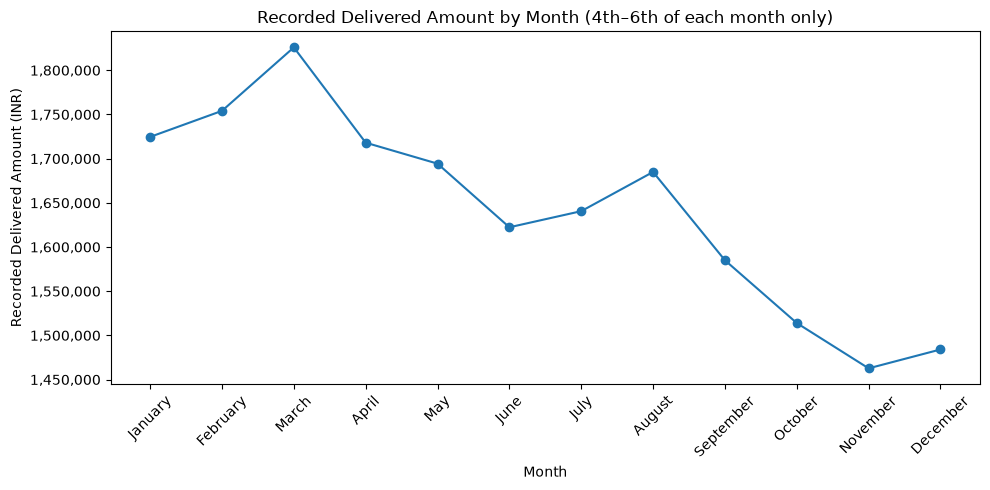

In [59]:
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(10, 5))

plt.plot(
    delivered_monthly["Month"],
    delivered_monthly["Delivered_Amount"],
    marker="o"
)

plt.title("Recorded Delivered Amount by Month (4th–6th of each month only)")
plt.xlabel("Month")
plt.ylabel("Recorded Delivered Amount (INR)")
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))

plt.tight_layout()
plt.show()

## 6.4 Compare delivered amount by category

I group Delivered item rows by product category and compare their recorded amount and quantity. This helps identify which categories contributed the most delivered amount in the dataset.

In [60]:
delivered_category = (
    delivered_rows
    .groupby("Category", as_index=False)
    .agg(
        Delivered_Amount=("Amount", "sum"),
        Delivered_Quantity=("Qty", "sum")
    )
    .sort_values("Delivered_Amount", ascending=False)
    .reset_index(drop=True)
)

delivered_category

,Category,Delivered_Amount,Delivered_Quantity
0,Set,9991114,11820
1,Kurta,4547130,9541
2,Western Dress,2787574,3607
3,Top,1114415,2048
4,Saree,933982,1275
5,Ethnic Dress,180643,245
6,Blouse,132170,221
7,Bottom,23516,65


In [61]:
delivered_category["Delivered_Amount"].sum(),delivered_rows["Amount"].sum()

(np.int64(19710544), np.int64(19710544))

**Finding:** Set had the highest delivered amount (9,991,114) and quantity (11,820). Bottom had the lowest delivered amount (23,516) and quantity (65). The category amounts reconcile with the delivered-item total.

## 6.5 Visualize delivered amount by category

I use a horizontal bar chart to compare the recorded delivered amount across product categories. I sort the bars so the largest category appears at the top.

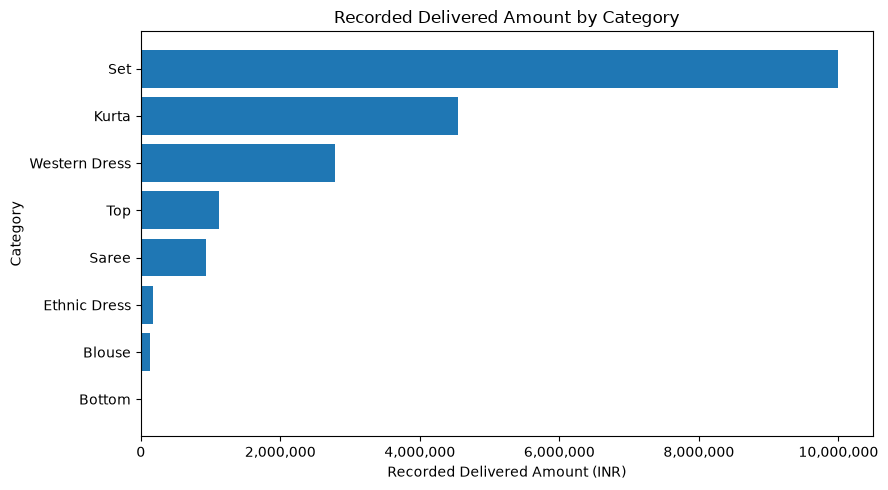

In [62]:
from matplotlib.ticker import FuncFormatter

category_plot = delivered_category.sort_values(
    "Delivered_Amount",
    ascending=True
)

plt.figure(figsize=(9, 5))
plt.barh(
    category_plot["Category"],
    category_plot["Delivered_Amount"]
)

plt.title("Recorded Delivered Amount by Category")
plt.xlabel("Recorded Delivered Amount (INR)")
plt.ylabel("Category")
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))

plt.tight_layout()
plt.show()

## 6.6 Compare non-delivered records by sales channel

I group Cancelled, Returned, and Refunded item rows by sales channel and count the records in each status. This shows how these records are distributed across channels


In [63]:
exception_channel = (
    df_clean[
        df_clean["Status"].isin(["Cancelled", "Returned", "Refunded"])
    ]
    .groupby(["Channel", "Status"])
    .size()
    .unstack(fill_value=0)
)

exception_channel

Status,Cancelled,Refunded,Returned
Channel,,,
Ajio,54,24,60
Amazon,308,201,383
Flipkart,188,113,229
Meesho,38,25,47
Myntra,188,116,237
Nalli,34,22,53
Others,34,16,36


In [64]:
channel_totals = df_clean.groupby("Channel").size()
non_delivered_rate = (exception_channel.sum(axis=1) / channel_totals * 100).round(2)
non_delivered_rate.sort_values(ascending=False)

Channel
Amazon      8.10
Flipkart    7.91
Meesho      7.87
Myntra      7.46
Nalli       7.35
Ajio        7.15
Others      6.82
dtype: float64

**Finding:** Amazon has the most Cancelled, Returned, and Refunded records (892 of 2,406; 37.1%), in line with it having the most records overall (11,016 of 31,047; 35.5%). As a share of each channel's own records, non-delivered rates are similar, from 6.82% (Others) to 8.10% (Amazon). These are record-level counts.

## 6.7 Visualize non-delivered records by sales channel

I use a bar chart to compare Cancelled, Returned, and Refunded records across sales channels.

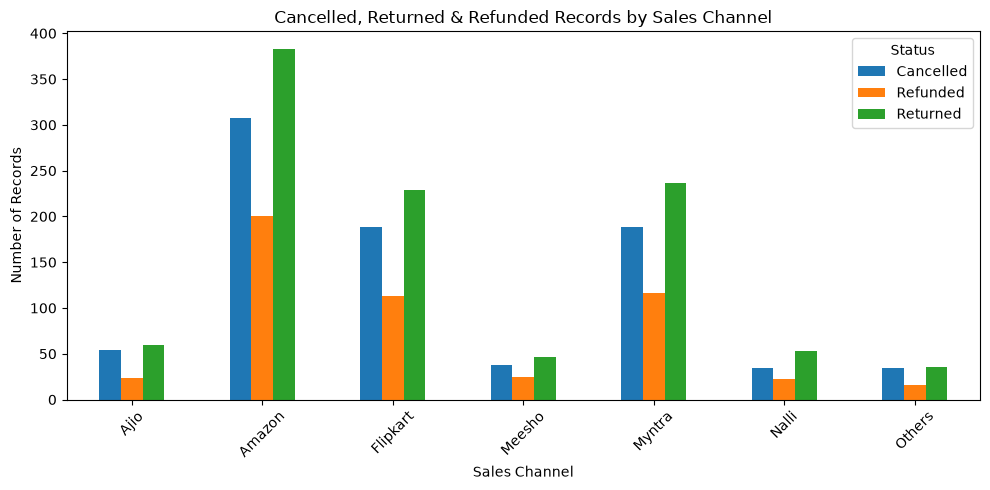

In [65]:
exception_channel.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Cancelled, Returned & Refunded Records by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 6.8 Compare delivered amount by sales channel

I group Delivered item rows by sales channel and compare their recorded delivered amount. This shows how the channels compare in this dataset.

In [66]:
delivered_channel = (
    delivered_rows.groupby("Channel", as_index=False)
    .agg(Delivered_Amount=("Amount", "sum"))
    .sort_values("Delivered_Amount", ascending=False)
)
delivered_channel

,Channel,Delivered_Amount
1,Amazon,6972495
4,Myntra,4617456
2,Flipkart,4252270
0,Ajio,1244810
5,Nalli,945211
3,Meesho,866133
6,Others,812169


**Finding** Amazon had the highest recorded delivered amount (6,972,495), while Others had the lowest (812,169). This describes the records in the dataset and does not show profit or the reason for the difference.

## 6.9 Compare delivered amount by gender

I group Delivered item rows by gender and compare their recorded delivered amount and quantity. This helps identify how delivered amount is distributed between Women and Men.

In [67]:
delivered_gender = (
    delivered_rows
    .groupby("Gender", as_index=False)
    .agg(
        Delivered_Amount=("Amount", "sum"),
        Delivered_Quantity=("Qty", "sum")
    )
    .sort_values("Delivered_Amount", ascending=False)
)

delivered_gender

,Gender,Delivered_Amount,Delivered_Quantity
1,Women,12666129,20026
0,Men,7044415,8796


## 6.10 Compare delivered performance by age group

I group delivered item rows into age bands based on the observed age range. The original `Age` column stays unchanged. I compare recorded delivered amount, quantity, and distinct customers across the groups.

In [68]:
age_bins = [17, 25, 35, 45, 55, 65, float("inf")]
age_labels = ["18-25", "26-35", "36-45", "46-55", "56-65", "66+"]

delivered_age = (
    delivered_rows.assign(
        Age_Group=pd.cut(
            delivered_rows["Age"],
            bins=age_bins,
            labels=age_labels
        )
    )
    .groupby("Age_Group", observed=False, as_index=False)
    .agg(
        Delivered_Amount=("Amount", "sum"),
        Delivered_Quantity=("Qty", "sum"),
        Unique_Customers=("Cust ID", "nunique")
    )
)

delivered_age

,Age_Group,Delivered_Amount,Delivered_Quantity,Unique_Customers
0,18-25,3940893,5781,5631
1,26-35,4987568,7291,7063
2,36-45,4925200,7195,6998
3,46-55,2780074,4047,3962
4,56-65,1322951,1962,1932
5,66+,1753858,2546,2509


In [69]:
print("Age-group amount total:", delivered_age["Delivered_Amount"].sum())
print("Overall delivered amount:", delivered_rows["Amount"].sum())

print(
    "Age-group amount reconciles:",
    delivered_age["Delivered_Amount"].sum() == delivered_rows["Amount"].sum()
)

Age-group amount total: 19710544
Overall delivered amount: 19710544
Age-group amount reconciles: True


**Data check:** I check whether each customer ID has consistent age and gender values across delivered item rows. This helps me judge whether customer comparisons by age or gender are reliable.

In [70]:
customer_profile = delivered_rows.groupby("Cust ID").agg(
    Age_Variants=("Age", "nunique"),
    Gender_Variants=("Gender", "nunique")
)

{
    "Unique customers": delivered_rows["Cust ID"].nunique(),
    "Customers with multiple ages": (customer_profile["Age_Variants"] > 1).sum(),
    "Customers with multiple gender labels": (customer_profile["Gender_Variants"] > 1).sum()
}

{'Unique customers': 26327,
 'Customers with multiple ages': np.int64(1830),
 'Customers with multiple gender labels': np.int64(622)}

**Data-quality finding:** Some customer IDs have inconsistent age or gender values across delivered item rows. Age-group and gender summaries therefore reflect the labels recorded on item rows and may count the same customer in multiple groups. I exclude customer-level age and gender comparisons from my conclusions.

## 6.11 Compare delivered amount by state

I group Delivered item rows by shipping state and compare their recorded delivered amount. The state comes from the `State` column in the `03_Data_processing` sheet of the Excel workbook. This shows where delivered item amounts are recorded in the dataset.

Check: I load the Data processed sheet that already contains the state for each record.

In [71]:
processed_data = pd.read_excel(
    "../data/full_cart_store_2022.xlsx",
    sheet_name="03_Data_processing "
)
processed_data["State"] = processed_data["State"].str.strip().str.upper()

processed_data.shape

(31047, 27)

Check: I keep only the Delivered item rows.

In [72]:
delivered_state = processed_data[
    processed_data["Status"] == "Delivered"
].copy()

delivered_state.shape

(28641, 27)

Check: I confirm that no record is missing a state.

In [73]:
processed_data["State"].isna().sum()

np.int64(0)

Check: I group the delivered rows by state and add the recorded amount.

In [74]:
state_amount = (
    delivered_state
    .groupby("State", as_index=False)
    .agg(Delivered_Amount=("Amount", "sum"))
    .sort_values("Delivered_Amount", ascending=False)
)

state_amount.head(10)

,State,Delivered_Amount
19,MAHARASHTRA,2780601
15,KARNATAKA,2440485
32,UTTAR PRADESH,1974615
30,TELANGANA,1578278
29,TAMIL NADU,1577166
8,DELHI,1206827
16,KERALA,927173
34,WEST BENGAL,849898
1,ANDHRA PRADESH,849114
11,HARYANA,765935


Check: The state totals should add up to the total delivered amount.

In [75]:
state_amount["Delivered_Amount"].sum(), delivered_state["Amount"].sum()

(np.int64(19710544), np.int64(19710544))

Check State-wise Delivered Amount

In [76]:
delivered_state_summary = (
    delivered_state
    .groupby("State", as_index=False)
    .agg(
        Delivered_Amount=("Amount", "sum")
    )
    .sort_values("Delivered_Amount", ascending=False)
    .reset_index(drop=True)
)

delivered_state_summary

,State,Delivered_Amount
0,MAHARASHTRA,2780601
1,KARNATAKA,2440485
2,UTTAR PRADESH,1974615
3,TELANGANA,1578278
4,TAMIL NADU,1577166
5,DELHI,1206827
6,KERALA,927173
7,WEST BENGAL,849898
8,ANDHRA PRADESH,849114
9,HARYANA,765935


Check: I select the ten states with the highest recorded delivered amount.

In [77]:
top_10_states = delivered_state_summary.head(10)

top_10_states

,State,Delivered_Amount
0,MAHARASHTRA,2780601
1,KARNATAKA,2440485
2,UTTAR PRADESH,1974615
3,TELANGANA,1578278
4,TAMIL NADU,1577166
5,DELHI,1206827
6,KERALA,927173
7,WEST BENGAL,849898
8,ANDHRA PRADESH,849114
9,HARYANA,765935


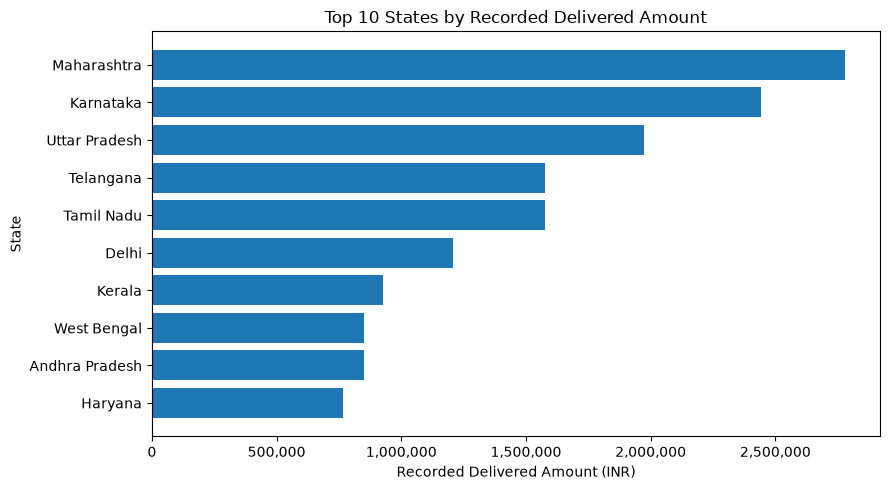

In [78]:
from matplotlib.ticker import FuncFormatter

top_10_states = delivered_state_summary.head(10).sort_values(
    "Delivered_Amount",
    ascending=True
)

plt.figure(figsize=(9, 5))
plt.barh(
    top_10_states["State"].str.title(),
    top_10_states["Delivered_Amount"]
)

plt.title("Top 10 States by Recorded Delivered Amount")
plt.xlabel("Recorded Delivered Amount (INR)")
plt.ylabel("State")
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))

plt.tight_layout()
plt.show()

**Finding:** Maharashtra had the highest recorded delivered amount (2,780,601; 14.1% of the Delivered Amount), followed by Karnataka (2,440,485) and Uttar Pradesh (1,974,615). State comes from the Excel `State` column, which is based on shipping city and PIN code; a few city/PIN mappings could not be fully verified.

## 6.12 Review the Order Status mix by record

I calculate the number and percentage of dataset rows for each status. Because one Order ID can appear under multiple statuses, these percentages describe rows, not whole orders.

In [79]:
status_mix = (
    df_clean["Status"]
    .value_counts()
    .rename_axis("Status")
    .reset_index(name="Record_Count")
)

status_mix["Percent_of_Records"] = (
    status_mix["Record_Count"] / len(df_clean) * 100
).round(2)

status_mix

,Status,Record_Count,Percent_of_Records
0,Delivered,28641,92.25
1,Returned,1045,3.37
2,Cancelled,844,2.72
3,Refunded,517,1.67


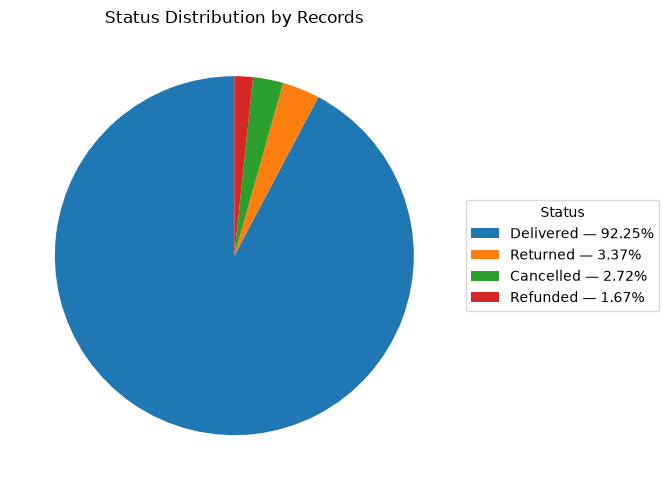

In [80]:
plt.figure(figsize=(8, 5))

plt.pie(
    status_mix["Record_Count"],
    startangle=90
)

legend_labels = [
    f"{status} — {percent:.2f}%"
    for status, percent in zip(
        status_mix["Status"],
        status_mix["Percent_of_Records"]
    )
]

plt.legend(
    legend_labels,
    title="Status",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Status Distribution by Records")

plt.tight_layout()
plt.show()

 **Finding:** Delivered rows make up 92.25% of the dataset records. Returned, Cancelled, and Refunded rows together make up 7.75% (2,406 records). These are record percentages, not order-level delivery or return rates.

**Note:** Percentages may sum to 100.01% because of rounding.

# 7. Key Findings

1. **Delivery status:** The dataset contains 31,047 item-level records across 28,471 unique Order IDs. Of these, 28,641 records (92.25%) are Delivered, with a total Delivered Amount of ₹19,710,544. This is a record-level share, not an order-level delivery rate.

2. **Non-delivered records:** 2,406 records (7.75%) are Returned (1,045; 3.37%), Cancelled (844; 2.72%) or Refunded (517; 1.67%). The data has no cost, margin or refund-amount fields, so financial loss cannot be calculated. 214 Order IDs carry more than one status, so these figures are record-level.

3. **Category:** Set has the highest Delivered Amount (₹9,991,114; 50.7%). Set, Kurta and Western Dress together account for 87.9% of the Delivered Amount. Bottom is the lowest (₹23,516; 0.12%).

4. **Sales channel:** Amazon has the most records (11,016; 35.5% of all records) and the highest Delivered Amount (₹6,972,495; 35.4%). Amazon, Myntra and Flipkart together account for 80.4% of the Delivered Amount. This compares recorded amounts only, not profitability.

5. **Non-delivered records by channel:** Amazon has the most Cancelled, Returned and Refunded records (892 of 2,406), in line with its overall volume. Measured against each channel's own records, non-delivered rates are similar, from 6.82% (Others) to 8.10% (Amazon).

6. **State:** Maharashtra has the highest Delivered Amount (₹2,780,601; 14.1%), followed by Karnataka (₹2,440,485) and Uttar Pradesh (₹1,974,615), together 36.5%. State comes from the workbook's `State` column, which is based on shipping city and PIN code. A few city/PIN mappings could not be fully verified (₹4,419, about 0.02% of the Delivered Amount), which is too small to change the top states.

7. **Monthly pattern:** Among the available records, Delivered Amount is highest in March (₹1,825,897) and lowest in November (₹1,462,714), with a small rise in December (₹1,484,065). The dataset covers only the 4th, 5th and 6th of each month (36 dates, Jan 4 to Dec 6), so each month reflects three days, not full-month performance. No cause is implied.

8. **Data quality limits:** 2,064 Order IDs appear on multiple rows, and rows sharing an Order ID often differ in channel, shipping PIN code, age or gender. Order ID is therefore treated as a non-unique record identifier. Among 26,327 Cust IDs with Delivered Records, 1,830 show more than one age and 622 more than one gender label. Age and gender comparisons are therefore excluded from the conclusions.

## 8. Recommendations and Follow-up Analysis

### Supported by the current findings

1. **Confirm identifier and mapping definitions with the data owner.** Check whether Order ID is meant to identify a single order, and verify the few city/PIN-to-state mappings against the official PIN directory. Do this before reporting order-level or state-level KPIs.
2. **Compare channels using rates, not raw counts.** Amazon's higher counts of Delivered and non-delivered records largely reflect its volume (Finding 5). Fees, advertising costs and margins would be needed before any channel-investment decision.
3. **Review the Set category's concentration (50.7% of the Delivered Amount) with stock, cost and return information.** Do this before making inventory decisions. The project shows the concentration but not its cause.

### Future analysis opportunities

4. **Deeper status analysis (possible with the current data).** Compare Returned, Cancelled and Refunded rates by category, size, SKU and state at record level. Add reason codes if they become available.
5. **Complete time-series analysis (needs full daily data).** Rebuild the monthly view with every day of each month before drawing any conclusion about seasonality or the March-to-November pattern.
6. **Profitability analysis (needs cost, margin, fee and refund-amount data).** Only then can profit and actual financial loss be measured.
7. **Customer-level analysis (needs reliable customer identifiers and verified demographics).** Revisit gender and age comparisons, and repeat-purchase behaviour, once `Cust ID` and the demographic fields are consistent.

## 9. Conclusion

I cleaned and analyzed 31,047 ecommerce records while keeping the original DataFrame unchanged. The analysis compared recorded delivered amounts by month, product category, sales channel, and shipping state. March had the highest recorded delivered amount among the available monthly records; Set had the highest recorded delivered amount by category; Amazon had the highest recorded delivered amount by channel; and Maharashtra had the highest recorded delivered amount by state. By record, 92.25% were Delivered and 7.75% (2,406 records) were Returned, Cancelled, or Refunded.

These findings describe the records in this dataset; they do not explain why the differences occurred or measure profit. Repeated Order IDs often differ in channel, shipping PIN code, age, or gender, so I treat Order ID as a non-unique record identifier and report status percentages at the record level. Some customer IDs also have inconsistent age or gender values, so I exclude age- and gender-based customer conclusions.

## 10. Save the cleaned dataset

I export `df_clean` as a CSV so it can be reused for analysis. The original `df` remains unchanged. The exported CSV does not include `State`, which comes from the `03_Data_processing` sheet of the Excel workbook.

In [81]:
df_clean.to_csv(
    "../data/cleaned_ecommerce_sales.csv",
    index=False
)

In [82]:
from pathlib import Path
Path("../data/cleaned_ecommerce_sales.csv").exists()

True

In [83]:
df_saved = pd.read_csv(
    "../data/cleaned_ecommerce_sales.csv",
    parse_dates=["Date"]
)

print("Saved shape:", df_saved.shape)
print("Saved columns:", len(df_saved.columns))
print("Index column exists:", "index" in df_saved.columns)
print("Missing values:", df_saved.isnull().sum().sum())
print("Qty dtype:", df_saved["Qty"].dtype)
print("Gender values:", sorted(df_saved["Gender"].unique()))
print("Category values:", sorted(df_saved["Category"].unique()))
print("Saved Date dtype:", df_saved["Date"].dtype)
print("Saved date range:", df_saved["Date"].min(), "to", df_saved["Date"].max())
print("Rows match:", len(df_saved) == len(df_clean))
print("Columns match:", list(df_saved.columns) == list(df_clean.columns))

Saved shape: (31047, 17)
Saved columns: 17
Index column exists: False
Missing values: 0
Qty dtype: int64
Gender values: ['Men', 'Women']
Category values: ['Blouse', 'Bottom', 'Ethnic Dress', 'Kurta', 'Saree', 'Set', 'Top', 'Western Dress']
Saved Date dtype: datetime64[us]
Saved date range: 2022-01-04 00:00:00 to 2022-12-06 00:00:00
Rows match: True
Columns match: True
